# 42173 Advanced Natural Language Processing
## Evaluation: standard RAG vs CRAG on PubHealth (Qwen2.5-3B generator)

This notebook compares **standard RAG** with **CRAG**, with the LLM on its own (no retrieval) as the baseline, on the
same 200 PubHealth health claims (true or false). The generator, prompt, claims and decoding are identical in every
setting, so any difference comes from the knowledge the generator is given.

| Setting | Knowledge given to the generator |
|---|---|
| No retrieval | none, the model answers from what it learnt in pre-training |
| Standard RAG | the top 5 health-filtered Wikipedia passages from Contriever |
| CRAG | the same passages after the retrieval evaluator, action trigger, knowledge refinement and web search |

**Sections**

1. Setup and settings
2. Run the three settings (saved per claim)
3. Run the ablations (saved per claim)
4. Results: standard RAG vs CRAG
5. Results: ablations and action thresholds
6. Results: quality of the knowledge itself
7. Example responses
8. Key findings

The group's code is used unchanged (`MODELS` and `CORPORA` from `scripts/evaluate.py`, `load_pubhealth`, `run_rag`,
`correct_knowledge`, `refine`, `rewrite_query`, `web_search`, `predict_label`). Every run step saves its results after
each claim, so when the results files already exist the notebook reuses them and only redoes the analysis.

## 1. Setup and settings

Open this notebook from the `notebooks/` folder of the repo (with `models/` and `indexes/`). On Google Colab, uncomment
the clone lines first. The requirements are installed only if something is missing.

In [1]:
# On Google Colab: uncomment to get the repo with its Git LFS model files
# !git lfs install
# !git clone https://github.com/hulemihi/42173-ANLP-CRAG.git
# %cd 42173-ANLP-CRAG/notebooks

import importlib.util
import subprocess
import sys

missing = [m for m in ("datasets", "transformers", "sentencepiece", "dotenv", "rank_bm25", "matplotlib")
           if importlib.util.find_spec(m) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "../requirements.txt"], check=True)

import json
import math
import os
import re
import time
import warnings
from pathlib import Path

os.environ.setdefault("HF_HUB_VERBOSITY", "error")          # no "unauthenticated requests" notices
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from tqdm import tqdm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "crag").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from crag import actions
from crag import evaluator as crag_evaluator
from crag.data import load_pubhealth
from crag.evaluator import evaluate_relevance, load_evaluator
from crag.generator import load_generator, predict_label
from crag.pipeline import check_crag_ready, correct_knowledge, run_rag
from crag.refinement import refine, split_into_strips
from crag.retriever import _encode, build_index, retrieve
from crag.web_search import rewrite_query, web_search

# The model and corpus tables come from scripts/evaluate.py, so the notebook and the script stay in sync

spec = importlib.util.spec_from_file_location("evaluate_script", ROOT / "scripts" / "evaluate.py")
evaluate_script = importlib.util.module_from_spec(spec)
spec.loader.exec_module(evaluate_script)
CORPUS = "wikipedia"                            # or "textbooks"
MODELS = evaluate_script.MODELS
LOAD_CORPUS, INDEX_PATH = evaluate_script.CORPORA[CORPUS]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NOTEBOOK_START = time.time()
pd.set_option("display.max_colwidth", 120)
print("Repo:", ROOT.name, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "",
      "| generators available:", list(MODELS))

Repo: 42173-ANLP-CRAG | device: cuda NVIDIA GeForce RTX 5060 Ti | generators available: ['0.5b', '3b', '7b']


In [2]:
MODEL_KEY = "3b"             # generator from MODELS: "0.5b", "3b" or "7b" (7b is 4-bit and needs a GPU)
N_CLAIMS = 200               # fixed, stratified PubHealth test subset (the same as scripts/evaluate.py)
K = 5                        # passages retrieved per claim
RUN_ABLATIONS = True         # section 3
N_EXAMPLES = 2               # claims answered again with a full explanation in section 7
FLOAT32_WITHOUT_BF16 = True  # on a CPU, or a GPU without bf16 such as the T4, run the bf16 weights in float32
RESUME = True                # reuse results already saved in results/
SEED = 42

In [3]:
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
TAG = f"pubhealth_n{N_CLAIMS}_{MODEL_KEY}_{CORPUS}_notebook"
RESULTS_PATH = RESULTS_DIR / f"crag_{TAG}.csv"                 # main comparison
ABLATION_PATH = RESULTS_DIR / f"crag_ablations_{TAG}.csv"      # ablations
BACKOFF_PATH = RESULTS_DIR / f"crag_backoff_{TAG}.csv"         # back-off search variant
KNOWLEDGE_PATH = RESULTS_DIR / f"crag_knowledge_{TAG}.jsonl"   # passages, strips, queries and web results

claims = load_pubhealth(n=N_CLAIMS)
claims.insert(0, "id", range(len(claims)))
explanations = dict(zip(claims.id, claims.explanation))

t0 = time.time()
index = build_index(LOAD_CORPUS(), cache_path=INDEX_PATH)
model, tokenizer = load_generator(**MODELS[MODEL_KEY])
has_bf16 = DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8   # Ampere or newer
if FLOAT32_WITHOUT_BF16 and not has_bf16 and not MODELS[MODEL_KEY].get("load_in_4bit"):
    model = model.float()
eval_model, eval_tokenizer = load_evaluator()
problems = check_crag_ready()

display(pd.DataFrame({
    "claims": [f"{len(claims)} ({(claims.label == 'true').sum()} true, {(claims.label == 'false').sum()} false)"],
    "generator": [f"{MODELS[MODEL_KEY]['model_name']} ({next(model.parameters()).dtype})"],
    "retrieval corpus": [f"{'Health-filtered Wikipedia' if CORPUS == 'wikipedia' else 'MedRAG Textbooks'}, {len(index.passages):,} passages, top {K}"],
    "action thresholds": [f"UPPER {actions.UPPER}, LOWER {actions.LOWER}"],
    "web search": ["Tavily + PubMed" if os.getenv("TAVILY_API_KEY") else "PubMed only (no TAVILY_API_KEY)"],
    "CRAG stages": ["ready" if not problems else "; ".join(problems)],
}).T.rename(columns={0: ""}))
print(f"Loaded in {time.time() - t0:.0f}s")

Loading weights: 100%|██████████| 51/51 [00:00<00:00, 3390.12it/s]


,
claims,"200 (121 true, 79 false)"
generator,Qwen/Qwen2.5-3B-Instruct (torch.bfloat16)
retrieval corpus,"Health-filtered Wikipedia, 1,211,956 passages, top 5"
action thresholds,"UPPER 0.91, LOWER 0.9"
web search,Tavily + PubMed
CRAG stages,ready


Loaded in 30s


## 2. Run the three settings

For each claim the label is predicted three times with `explain=False`, as in `scripts/evaluate.py`: one forward pass,
and the label with the higher next-token probability wins. CRAG follows `pipeline.run_crag` step by step so that the
evaluator scores and the size of the corrected knowledge can be saved too. Claims already in the results file are
skipped.

In [4]:
WEB_PREFIXES = ("[PubMed]", "[Web]")
LABEL_COLUMNS = ["gold", "no_retrieval", "rag", "crag"]
C, I, A = actions.CORRECT, actions.INCORRECT, actions.AMBIGUOUS


def as_labels(frame, columns):
    """pandas reads the words true / false back from a CSV as booleans, so turn every label back into the word."""
    for c in columns:
        if c in frame.columns:
            frame[c] = frame[c].map(lambda v: str(v).strip().lower())
    return frame


def evaluate_claim(claim):
    row = {}
    t = time.time()
    none = predict_label(model, tokenizer, claim, [], explain=False)
    row.update(no_retrieval=none.label, no_retrieval_p_true=none.probs["true"], seconds_no_retrieval=time.time() - t)

    t = time.time()
    rag = run_rag(claim, index, model, tokenizer, k=K, explain=False)
    row.update(rag=rag.label, rag_p_true=rag.probs["true"], seconds_rag=time.time() - t)

    t = time.time()
    passages = retrieve(index, claim, k=K)
    knowledge, action, scores = correct_knowledge(claim, passages, eval_model, eval_tokenizer,
                                                  gen_model=model, gen_tokenizer=tokenizer)
    crag = predict_label(model, tokenizer, claim, knowledge, explain=False)
    row.update(crag=crag.label, crag_p_true=crag.probs["true"], crag_action=action,
               crag_scores=json.dumps([round(float(s), 4) for s in scores]), crag_max_score=max(scores),
               crag_knowledge_items=len(knowledge),
               crag_web_items=sum(k.startswith(WEB_PREFIXES) for k in knowledge),
               crag_knowledge_words=sum(len(k.split()) for k in knowledge),
               seconds_crag=time.time() - t)
    return row


rows = []
if RESUME and RESULTS_PATH.exists():
    rows = as_labels(pd.read_csv(RESULTS_PATH), LABEL_COLUMNS).to_dict("records")
done = {r["id"] for r in rows}
todo = [r for r in claims.itertuples() if r.id not in done]
print(f"{len(done)} claims reused from {RESULTS_PATH.name}, {len(todo)} to run")
for r in tqdm(todo, desc="Main comparison"):
    rows.append({"id": r.id, "claim": r.claim, "gold": r.label, **evaluate_claim(r.claim)})
    pd.DataFrame(rows).sort_values("id").to_csv(RESULTS_PATH, index=False)

results = as_labels(pd.DataFrame(rows).sort_values("id").reset_index(drop=True), LABEL_COLUMNS)
results = results[results.id.isin(claims.id)].reset_index(drop=True)
results.to_csv(RESULTS_PATH, index=False)
results[["claim", "gold", "no_retrieval", "rag", "crag", "crag_action"]].head()

37 claims reused from crag_pubhealth_n200_3b_wikipedia_notebook.csv, 163 to run


Main comparison: 100%|██████████| 163/163 [03:12<00:00,  1.18s/it]


,claim,gold,no_retrieval,rag,crag,crag_action
0,"U.S. President Donald Trump tweeted in November 2009 that ""Obama's handling of this whole pandemic has been terrible...",false,false,false,false,incorrect
1,An habitual alcohol abuser lost his penis to frostbite after a drunken sexual encounter with a snowman.,false,false,false,false,incorrect
2,"Liberals"" want to change the name of Cracker Barrel to ""Caucasian Barrel"" because otherwise it's racist.",false,false,false,false,incorrect
3,"The IRS is going to be ""in charge"" of ""a huge national database"" on health care that will include Americans’ ""person...",false,false,false,false,incorrect
4,A video shows a man demonstrating an invisibility cloak.,false,false,false,false,incorrect


## 3. Run the ablations

Each variant changes one part of CRAG and keeps everything else (claims, passages, evaluator scores, generator) the
same, following the ablations in the CRAG paper (Tables 2, 3 and 11):

| Variant | Knowledge given to the generator |
|---|---|
| CRAG w/o refinement | whole passages instead of the refined strips |
| CRAG w/o query rewriting | web search with the claim itself instead of the rewritten keywords |
| CRAG w/o web search | refined strips only (Incorrect therefore gets no knowledge) |
| CRAG with back-off search | *notebook-only*: if PubMed finds nothing, search again with the first 4, 3 or 2 keywords |
| Correct / Incorrect / Ambiguous for every claim | one action forced for all claims (also used for the threshold analysis) |
| Oracle context | the fact-checkers' own explanation of the claim (an upper bound, not a real system) |

The back-off variant exists because the rewritten query is a list of keywords and PubMed only returns articles that
match all of them, so CRAG's web search often finds nothing. A forward pass only runs when a variant's knowledge
differs from knowledge already scored for that claim.

In [5]:
ABLATIONS = {"crag_no_refine": "CRAG w/o refinement", "crag_no_rewrite": "CRAG w/o query rewriting",
             "crag_no_web": "CRAG w/o web search", "crag_backoff": "CRAG with back-off search",
             "all_correct": "Correct for every claim", "all_incorrect": "Incorrect for every claim",
             "all_ambiguous": "Ambiguous for every claim", "oracle": "Oracle context"}
BACKOFF_COLUMNS = ["crag_backoff", "crag_backoff_p_true", "backoff_web_items", "query_backoff"]


def score_fn(question, text):
    return evaluate_relevance(eval_model, eval_tokenizer, question, text)


def predict_known(claim, knowledge, known):
    """Label for this knowledge, reusing a prediction already made for the same knowledge."""
    key = tuple(k for k in knowledge if k and k.strip())
    if key not in known:
        pred = predict_label(model, tokenizer, claim, list(key), explain=False)
        known[key] = (pred.label, pred.probs["true"])
    return known[key]


def crag_knowledge_of(rec):
    return {C: rec["refined"], I: rec["web"], A: rec["refined"] + rec["web"]}[rec["action"]]


def ablate_claim(row):
    claim = row["claim"]
    passages = retrieve(index, claim, k=K)
    scores = [score_fn(claim, p) for p in passages]
    action = actions.decide_action(scores)
    refined = refine(claim, passages, score_fn)
    query = rewrite_query(claim, model=model, tokenizer=tokenizer)
    web, web_raw = web_search(query), web_search(claim)
    rec = {"id": row["id"], "claim": claim, "gold": row["gold"], "action": action,
           "scores": [round(float(s), 4) for s in scores], "passages": passages, "refined": refined,
           "query": query, "web": web, "web_raw": web_raw}
    variants = {"crag_no_refine": {C: passages, I: web, A: passages + web}[action],
                "crag_no_rewrite": {C: refined, I: web_raw, A: refined + web_raw}[action],
                "crag_no_web": {C: refined, I: [], A: refined}[action],
                "all_correct": refined, "all_incorrect": web, "all_ambiguous": refined + web,
                "oracle": [explanations[row["id"]]]}
    known = {(): (row["no_retrieval"], row["no_retrieval_p_true"]),
             tuple(passages): (row["rag"], row["rag_p_true"]),
             tuple(crag_knowledge_of(rec)): (row["crag"], row["crag_p_true"])}
    out = {"id": row["id"], "action_check": action, "query": query, "refined_strips": len(refined),
           "web_items": len(web), "raw_web_items": len(web_raw)}
    for name, knowledge in variants.items():
        out[name], out[f"{name}_p_true"] = predict_known(claim, knowledge, known)
    return out, rec


def backoff_search(query):
    """web_search with the rewritten keywords; if nothing is found, retry with the first 4, 3, then 2 of them."""
    parts = [p.strip() for p in re.split(r"[,;\n]+", query) if p.strip()]
    if len(parts) < 2:
        parts = query.split()
    tried = []
    for n in [len(parts), 4, 3, 2]:
        q = " ".join(parts[:n])
        if n > len(parts) or q in tried:
            continue
        tried.append(q)
        found = web_search(q)
        if found:
            return found, q
    return [], tried[-1] if tried else query


def backoff_claim(rec, row, abl_row):
    if rec["action"] == C:  # Correct never searches the web, so the variant equals CRAG
        return {"id": rec["id"], "crag_backoff": row["crag"], "crag_backoff_p_true": row["crag_p_true"],
                "backoff_web_items": 0, "query_backoff": ""}
    web_b, query_b = backoff_search(rec["query"])
    known = {(): (row["no_retrieval"], row["no_retrieval_p_true"]),
             tuple(crag_knowledge_of(rec)): (row["crag"], row["crag_p_true"]),
             tuple(rec["refined"]): (abl_row["all_correct"], abl_row["all_correct_p_true"])}
    label, p_true = predict_known(row["claim"], {I: web_b, A: rec["refined"] + web_b}[rec["action"]], known)
    return {"id": rec["id"], "crag_backoff": label, "crag_backoff_p_true": p_true,
            "backoff_web_items": len(web_b), "query_backoff": query_b}


def load_rows(path, columns):
    return as_labels(pd.read_csv(path), columns).to_dict("records") if RESUME and path.exists() else []


abl_rows = load_rows(ABLATION_PATH, list(ABLATIONS))
records = {}
if abl_rows and KNOWLEDGE_PATH.exists():
    records = {r["id"]: r for r in (json.loads(l) for l in KNOWLEDGE_PATH.read_text().splitlines() if l.strip())}
abl_rows = [r for r in abl_rows if r["id"] in records]           # keep the two files in step
KNOWLEDGE_PATH.write_text("".join(json.dumps(records[r["id"]]) + "\n" for r in abl_rows))
bo_rows = load_rows(BACKOFF_PATH, ["crag_backoff"])

if RUN_ABLATIONS:
    rows_by_id = results.set_index("id", drop=False).to_dict("index")
    todo = [r for r in results.to_dict("records") if r["id"] not in {a["id"] for a in abl_rows}]
    print(f"Ablations: {len(abl_rows)} claims reused, {len(todo)} to run")
    for row in tqdm(todo, desc="Ablations"):
        out, rec = ablate_claim(row)
        abl_rows.append(out)
        records[rec["id"]] = rec
        with open(KNOWLEDGE_PATH, "a") as f:
            f.write(json.dumps(rec) + "\n")
        pd.DataFrame(abl_rows).sort_values("id").to_csv(ABLATION_PATH, index=False)

    abl_by_id = {r["id"]: r for r in abl_rows}
    todo = [i for i in sorted(records) if i not in {b["id"] for b in bo_rows} and i in rows_by_id]
    print(f"Back-off search: {len(bo_rows)} claims reused, {len(todo)} to run")
    for i in tqdm(todo, desc="Back-off search"):
        bo_rows.append(backoff_claim(records[i], rows_by_id[i], abl_by_id[i]))
        pd.DataFrame(bo_rows).sort_values("id").to_csv(BACKOFF_PATH, index=False)

ablations = None
if abl_rows:
    ablations = as_labels(pd.DataFrame(abl_rows), list(ABLATIONS))
    ablations = ablations.drop(columns=[c for c in BACKOFF_COLUMNS if c in ablations.columns])
    if bo_rows:
        ablations = ablations.merge(as_labels(pd.DataFrame(bo_rows), ["crag_backoff"]), on="id")
    ablations = ablations.sort_values("id").reset_index(drop=True)
    same = (ablations.set_index("id").action_check == results.set_index("id").crag_action).mean()
    print(f"{len(ablations)} claims with ablations; CRAG action reproduced for {same:.0%} of them")

Ablations: 0 claims reused, 200 to run


Ablations: 100%|██████████| 200/200 [36:35<00:00, 10.98s/it]


Back-off search: 0 claims reused, 200 to run


Back-off search: 100%|██████████| 200/200 [00:50<00:00,  3.95it/s]

200 claims with ablations; CRAG action reproduced for 100% of them


## 4. Results: standard RAG vs CRAG

**How to read the table**

- **Accuracy** is the share of claims labelled correctly, with a 95% bootstrap interval. Always answering "true" already
  scores 60.5% here, because 121 of the 200 claims are true.
- **Macro F1** and **balanced accuracy** weight the true and false classes equally, so a model that always gives the
  same answer cannot look good on them. **AUROC** asks whether the generator's P(true) is higher for true claims than
  for false ones; 0.5 is chance.
- The **paired test** compares two settings on the same claims (exact McNemar test on the claims where they disagree);
  p < 0.05 means the difference is unlikely to be chance.

In [6]:
SETTINGS = {"no_retrieval": "No retrieval", "rag": "Standard RAG", "crag": "CRAG"}
COLOURS = {"No retrieval": "#64748B", "Standard RAG": "#D97706", "CRAG": "#4F46E5", "Oracle context": "#10B981"}
LABELS = ("true", "false")
_boot = {}


def boot(n):
    """2,000 bootstrap resamples of n claims, shared by every setting so that differences are paired."""
    if n not in _boot:
        _boot[n] = np.random.default_rng(SEED).integers(0, n, size=(2000, n))
    return _boot[n]


def macro_f1(gold, pred):
    f1s = []
    for label in LABELS:
        tp = ((pred == label) & (gold == label)).sum()
        fp = ((pred == label) & (gold != label)).sum()
        fn = ((pred != label) & (gold == label)).sum()
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        f1s.append(2 * p * r / (p + r) if p + r else 0.0)
    return float(np.mean(f1s))


def auroc(gold, p_true):
    ranks = pd.Series(p_true).rank().to_numpy()
    pos = np.asarray(gold) == "true"
    return float((ranks[pos].sum() - pos.sum() * (pos.sum() + 1) / 2) / (pos.sum() * (~pos).sum()))


def evaluate(frame, cols):
    out = {}
    for col, name in cols.items():
        correct = (frame[col] == frame.gold).to_numpy(float)
        lo, hi = np.percentile(correct[boot(len(correct))].mean(axis=1), [2.5, 97.5])
        out[name] = {"accuracy": correct.mean(), "ci_low": lo, "ci_high": hi,
                     "macro_f1": macro_f1(frame.gold, frame[col]),
                     "balanced_accuracy": float(np.mean([(frame[col][frame.gold == l] == l).mean() for l in LABELS])),
                     "auroc_p_true": auroc(frame.gold, frame[f"{col}_p_true"]),
                     "predicted_true": int((frame[col] == "true").sum()),
                     "mean_p_true": frame[f"{col}_p_true"].mean()}
    return pd.DataFrame(out).T.astype(float)


def mcnemar(a_ok, b_ok):
    only_a, only_b = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    n = only_a + only_b
    p = min(1.0, 2 * sum(math.comb(n, i) for i in range(min(only_a, only_b) + 1)) / 2 ** n) if n else 1.0
    return only_a, only_b, p


def compare(frame, a, b, names):
    a_ok, b_ok = (frame[a] == frame.gold).to_numpy(), (frame[b] == frame.gold).to_numpy()
    only_a, only_b, p = mcnemar(a_ok, b_ok)
    idx = boot(len(a_ok))
    lo, hi = np.percentile(a_ok.astype(float)[idx].mean(axis=1) - b_ok.astype(float)[idx].mean(axis=1), [2.5, 97.5])
    return {"comparison": f"{names[a]} vs {names[b]}", "difference": a_ok.mean() - b_ok.mean(), "ci_low": lo,
            "ci_high": hi, "only first right": only_a, "only second right": only_b, "p_value": p,
            "significant": "yes" if p < 0.05 else "no"}


def show(frame, pct=(), dec=(), ints=("predicted_true", "claims", "true_claims", "web_results", "no_knowledge",
                                       "pairs", "claims_with_no_knowledge", "only first right", "only second right")):
    fmt = {**{c: "{:.1%}" for c in pct}, **{c: "{:.3f}" for c in dec}, **{c: "{:.0f}" for c in ints}}
    display(frame.style.format({k: v for k, v in fmt.items() if k in frame.columns}))


always_true = (results.gold == "true").mean()
summary = evaluate(results, SETTINGS)
summary["seconds_per_claim"] = [results[f"seconds_{c}"].mean() for c in SETTINGS]
paired = pd.DataFrame([compare(results, a, b, SETTINGS)
                       for a, b in [("crag", "rag"), ("rag", "no_retrieval"), ("crag", "no_retrieval")]])

display(Markdown(f"**Main comparison** ({len(results)} claims; always answering 'true' gives {always_true:.1%})"))
show(summary, pct=["accuracy", "ci_low", "ci_high"],
     dec=["macro_f1", "balanced_accuracy", "auroc_p_true", "mean_p_true", "seconds_per_claim"])
display(Markdown("**Paired tests**"))
show(paired.set_index("comparison"), pct=["difference", "ci_low", "ci_high"], dec=["p_value"])

reference = []
for path, name in [(RESULTS_DIR / "crag_pubhealth_n200_0.5b.csv", "Qwen2.5-0.5B, group's earlier run"),
                   (RESULTS_DIR / "rag_pubhealth_n200_3b.csv", "Qwen2.5-3B, group's earlier run (no CRAG)")]:
    if path.exists() and path != RESULTS_PATH:
        old = as_labels(pd.read_csv(path), LABEL_COLUMNS)
        reference.append({"run": name, **{n: (old[c] == old.gold).mean() if c in old else np.nan
                                          for c, n in SETTINGS.items()}})
reference.append({"run": f"Qwen2.5-{MODEL_KEY.upper()}, this notebook", **summary.accuracy.to_dict()})
reference += [{"run": "LLaMA2-hf-7b, CRAG paper", "No retrieval": np.nan, "Standard RAG": 0.489, "CRAG": 0.595},
              {"run": "SelfRAG-LLaMA2-7b, CRAG paper", "No retrieval": np.nan, "Standard RAG": 0.390, "CRAG": 0.756}]
display(Markdown("**Reference points** (accuracy; the CRAG paper used LLaMA2 generators and Wikipedia retrieval)"))
show(pd.DataFrame(reference).set_index("run"), pct=list(SETTINGS.values()))

**Main comparison** (200 claims; always answering 'true' gives 60.5%)

,accuracy,ci_low,ci_high,macro_f1,balanced_accuracy,auroc_p_true,predicted_true,mean_p_true,seconds_per_claim
No retrieval,41.5%,35.0%,48.5%,0.341,0.508,0.564,12,0.070,0.052
Standard RAG,48.0%,41.0%,54.5%,0.436,0.564,0.609,23,0.116,0.297
CRAG,70.5%,64.0%,77.0%,0.705,0.732,0.779,84,0.415,0.820


**Paired tests**

,difference,ci_low,ci_high,only first right,only second right,p_value,significant
comparison,,,,,,,
CRAG vs Standard RAG,22.5%,15.0%,30.5%,57,12,0.000,yes
Standard RAG vs No retrieval,6.5%,2.0%,11.5%,19,6,0.015,yes
CRAG vs No retrieval,29.0%,21.5%,37.0%,68,10,0.000,yes


**Reference points** (accuracy; the CRAG paper used LLaMA2 generators and Wikipedia retrieval)

,No retrieval,Standard RAG,CRAG
run,,,
"Qwen2.5-0.5B, group's earlier run",39.0%,39.5%,49.0%
"Qwen2.5-3B, group's earlier run (no CRAG)",41.5%,41.5%,nan%
"Qwen2.5-3B, this notebook",41.5%,48.0%,70.5%
"LLaMA2-hf-7b, CRAG paper",nan%,48.9%,59.5%
"SelfRAG-LLaMA2-7b, CRAG paper",nan%,39.0%,75.6%


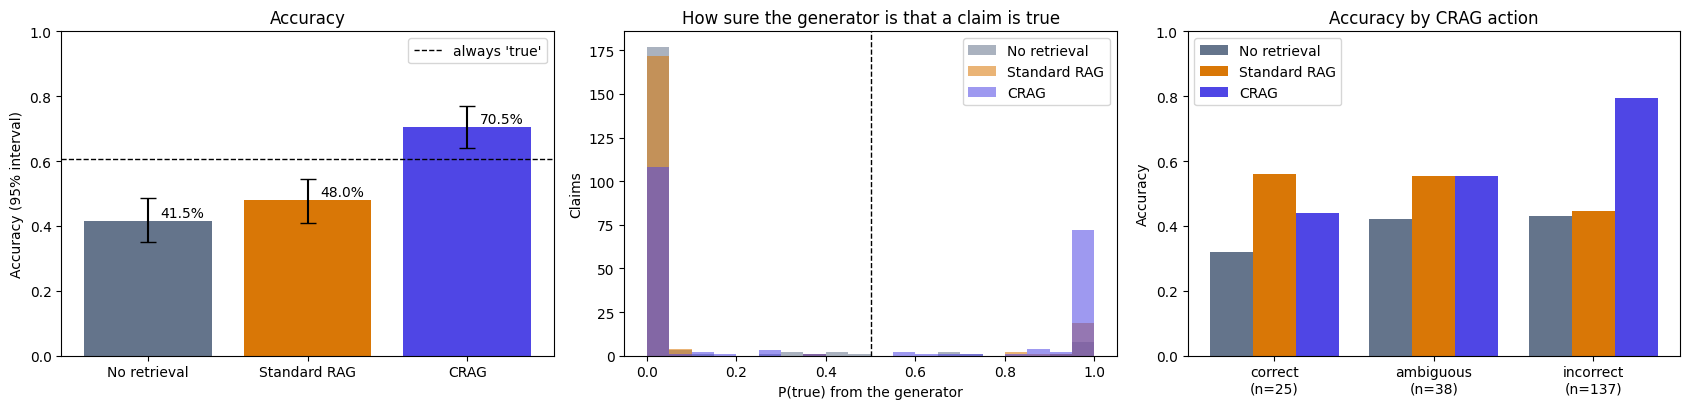

**By CRAG action** (web_results = claims where the web search returned anything; no_knowledge = claims where CRAG gave the generator nothing)

,claims,true_claims,no_retrieval,rag,crag,mean_max_score,web_results,no_knowledge,mean_words
crag_action,,,,,,,,,
correct,25,17,32.0%,56.0%,44.0%,0.914,0,0,238.120000
ambiguous,38,23,42.1%,55.3%,55.3%,0.905,38,0,1076.052632
incorrect,137,81,43.1%,44.5%,79.6%,0.683,137,0,842.562044


**Confusion matrices** (rows = gold label, columns = predicted label)

setting    No retrieval       Standard RAG       CRAG      
predicted          true false         true false true false
gold label                                                 
true                  8   113           20   101   73    48
false                 4    75            3    76   11    68

In [7]:
for col in SETTINGS:
    results[f"{col}_correct"] = results[col] == results.gold
ORDER = [a for a in ["correct", "ambiguous", "incorrect"] if a in set(results.crag_action)]
by_action = (results.groupby("crag_action")
             .agg(claims=("id", "size"), true_claims=("gold", lambda g: int((g == "true").sum())),
                  no_retrieval=("no_retrieval_correct", "mean"), rag=("rag_correct", "mean"),
                  crag=("crag_correct", "mean"), mean_max_score=("crag_max_score", "mean"),
                  web_results=("crag_web_items", lambda s: int((s > 0).sum())),
                  no_knowledge=("crag_knowledge_items", lambda s: int((s == 0).sum())),
                  mean_words=("crag_knowledge_words", "mean"))
             .reindex(ORDER))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
names = list(summary.index)
axes[0].bar(names, summary.accuracy, color=[COLOURS[n] for n in names],
            yerr=[summary.accuracy - summary.ci_low, summary.ci_high - summary.accuracy], capsize=6)
axes[0].axhline(always_true, ls="--", color="black", lw=1, label="always 'true'")
for i, v in enumerate(summary.accuracy):
    axes[0].text(i + 0.08, v + 0.012, f"{v:.1%}")
axes[0].set(ylim=(0, 1), ylabel="Accuracy (95% interval)", title="Accuracy")
axes[0].legend(loc="upper right")
for col, name in SETTINGS.items():
    axes[1].hist(results[f"{col}_p_true"], bins=np.linspace(0, 1, 21), alpha=0.55, color=COLOURS[name], label=name)
axes[1].axvline(0.5, ls="--", color="black", lw=1)
axes[1].set(xlabel="P(true) from the generator", ylabel="Claims", title="How sure the generator is that a claim is true")
axes[1].legend()
x = np.arange(len(ORDER))
for j, (col, name) in enumerate(SETTINGS.items()):
    axes[2].bar(x + (j - 1) * 0.27, by_action[col], width=0.27, color=COLOURS[name], label=name)
axes[2].set_xticks(x, [f"{a}\n(n={n})" for a, n in zip(ORDER, by_action.claims)])
axes[2].set(ylim=(0, 1), ylabel="Accuracy", title="Accuracy by CRAG action")
axes[2].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"fig_main_{TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

display(Markdown("**By CRAG action** (web_results = claims where the web search returned anything; "
                 "no_knowledge = claims where CRAG gave the generator nothing)"))
show(by_action, pct=["no_retrieval", "rag", "crag"], dec=["mean_max_score"])
confusion = pd.concat({SETTINGS[c]: pd.crosstab(results.gold, results[c]).reindex(index=LABELS, columns=LABELS,
                                                                                    fill_value=0) for c in SETTINGS},
                      axis=1)
confusion.index.name = "gold label"
confusion.columns.names = ["setting", "predicted"]
display(Markdown("**Confusion matrices** (rows = gold label, columns = predicted label)"))
display(confusion)

## 5. Results: ablations and action thresholds

Each ablation is compared with CRAG on the same claims. The forced-action variants give the prediction each action
would lead to for every claim, so CRAG's accuracy can be computed exactly for any pair of thresholds without running
the generator again (the thresholds in `src/crag/actions.py` are still placeholders).

**Ablations** (200 claims). Of the 175 claims where CRAG searches the web, PubMed returned results for 175 with the rewritten query, 175 with the raw claim and 175 with the back-off search.

,accuracy,ci_low,ci_high,vs CRAG,macro_f1,balanced_accuracy,auroc_p_true,predicted_true
No retrieval,41.5%,35.0%,48.5%,-29.0%,0.341,0.508,0.564,12
Standard RAG,48.0%,41.0%,54.5%,-22.5%,0.436,0.564,0.609,23
CRAG,70.5%,64.0%,77.0%,0.0%,0.705,0.732,0.779,84
CRAG w/o refinement,72.5%,66.0%,78.5%,2.0%,0.725,0.751,0.791,86
CRAG w/o query rewriting,77.0%,71.0%,83.0%,6.5%,0.766,0.777,0.825,105
CRAG w/o web search,44.0%,37.0%,50.5%,-26.5%,0.392,0.522,0.619,23
CRAG with back-off search,70.5%,64.0%,77.0%,0.0%,0.705,0.732,0.781,84
Correct for every claim,44.5%,37.5%,51.0%,-26.0%,0.392,0.530,0.595,20
Incorrect for every claim,73.5%,67.0%,79.5%,3.0%,0.734,0.752,0.780,94
Ambiguous for every claim,68.5%,62.0%,75.0%,-2.0%,0.685,0.713,0.773,82


**Each variant against CRAG** (paired McNemar test)

,difference,only first right,only second right,p_value,significant
comparison,,,,,
CRAG w/o refinement vs CRAG,2.0%,5,1,0.219,no
CRAG w/o query rewriting vs CRAG,6.5%,25,12,0.047,yes
CRAG w/o web search vs CRAG,-26.5%,7,60,0.000,yes
CRAG with back-off search vs CRAG,0.0%,0,0,1.000,no
Correct for every claim vs CRAG,-26.0%,8,60,0.000,yes
Incorrect for every claim vs CRAG,3.0%,10,4,0.180,no
Ambiguous for every claim vs CRAG,-2.0%,10,14,0.541,no
Oracle context vs CRAG,-2.0%,33,37,0.720,no


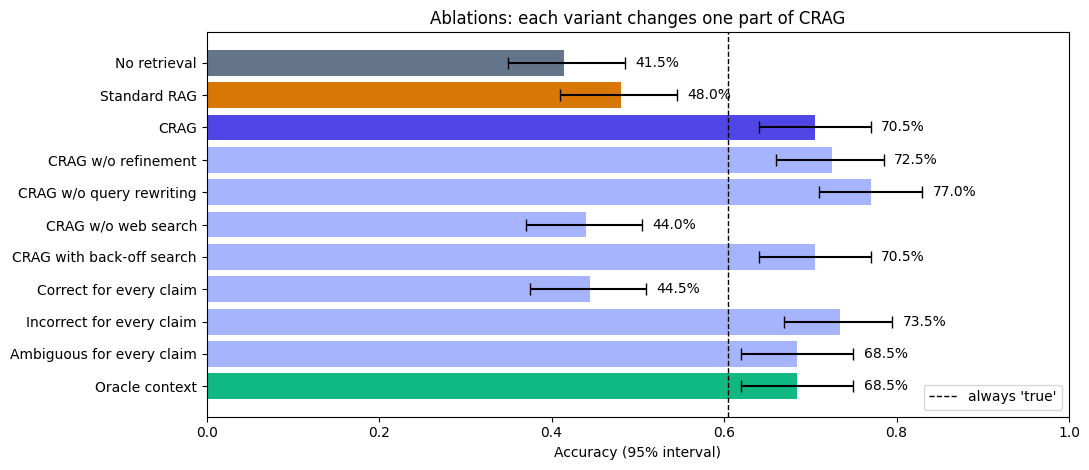

In [8]:
if ablations is not None:
    abl = results.merge(ablations, on="id")
    ALL = {**SETTINGS, **{k: v for k, v in ABLATIONS.items() if k in abl.columns}}
    abl_summary = evaluate(abl, ALL)
    abl_summary.insert(3, "vs CRAG", abl_summary.accuracy - abl_summary.loc["CRAG", "accuracy"])
    abl_tests = pd.DataFrame([compare(abl, v, "crag", ALL) for v in ALL if v not in SETTINGS])
    searched = abl.crag_action != C

    display(Markdown(f"**Ablations** ({len(abl)} claims). Of the {searched.sum()} claims where CRAG searches the web, "
                     f"PubMed returned results for {int((abl.web_items[searched] > 0).sum())} with the rewritten "
                     f"query, {int((abl.raw_web_items[searched] > 0).sum())} with the raw claim and "
                     f"{int((abl.backoff_web_items[searched] > 0).sum())} with the back-off search."))
    show(abl_summary.drop(columns=["mean_p_true"]), pct=["accuracy", "ci_low", "ci_high", "vs CRAG"],
         dec=["macro_f1", "balanced_accuracy", "auroc_p_true"])
    display(Markdown("**Each variant against CRAG** (paired McNemar test)"))
    show(abl_tests.set_index("comparison").drop(columns=["ci_low", "ci_high"]), pct=["difference"], dec=["p_value"])

    order = list(abl_summary.index)
    fig, ax = plt.subplots(figsize=(11, 4.8))
    ax.barh(order[::-1], abl_summary.accuracy[::-1], color=[COLOURS.get(n, "#A5B4FC") for n in order[::-1]],
            xerr=[(abl_summary.accuracy - abl_summary.ci_low)[::-1], (abl_summary.ci_high - abl_summary.accuracy)[::-1]],
            capsize=4)
    ax.axvline(always_true, ls="--", color="black", lw=1, label="always 'true'")
    for y, (v, hi) in enumerate(zip(abl_summary.accuracy[::-1], abl_summary.ci_high[::-1])):
        ax.text(hi + 0.012, y, f"{v:.1%}", va="center")
    ax.set(xlim=(0, 1), xlabel="Accuracy (95% interval)", title="Ablations: each variant changes one part of CRAG")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"fig_ablations_{TAG}.png", dpi=200, bbox_inches="tight")
    plt.show()

ValueError: 0.91 is not in list

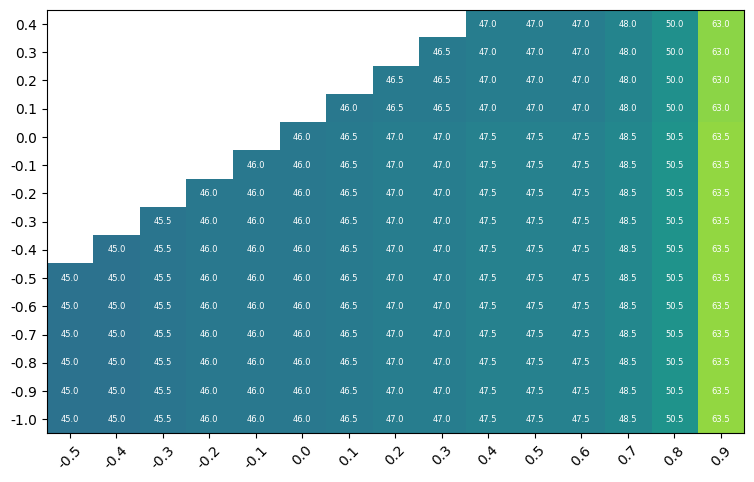

In [9]:
if ablations is not None:
    scores_by_id = {i: json.loads(s) for i, s in zip(results.id, results.crag_scores)}
    forced = {C: dict(zip(abl.id, abl.all_correct)), I: dict(zip(abl.id, abl.all_incorrect)),
              A: dict(zip(abl.id, abl.all_ambiguous))}
    gold = dict(zip(abl.id, abl.gold))

    def accuracy_at(upper, lower):
        return np.mean([forced[actions.decide_action(scores_by_id[i], upper=upper, lower=lower)][i] == gold[i]
                        for i in abl.id])

    uppers = np.round(np.arange(-0.5, 1.0, 0.1), 2)
    lowers = np.round(np.arange(-1.0, 0.5, 0.1), 2)
    grid = pd.DataFrame([[accuracy_at(u, l) if l <= u else np.nan for u in uppers] for l in lowers],
                        index=lowers, columns=uppers)
    best = grid.stack().idxmax()
    acc_now = accuracy_at(actions.UPPER, actions.LOWER)

    fig, ax = plt.subplots(figsize=(9, 5.5))
    # fixed colour scale around the always-'true' baseline, so small differences are not exaggerated
    im = ax.imshow(grid.values, origin="lower", cmap="viridis", aspect="auto", vmin=0.3, vmax=0.7)
    ax.set_xticks(range(len(uppers)), [f"{u + 0.0:.1f}" for u in uppers], rotation=45)
    ax.set_yticks(range(len(lowers)), [f"{l + 0.0:.1f}" for l in lowers])
    for y in range(len(lowers)):
        for x in range(len(uppers)):
            if not np.isnan(grid.values[y, x]):
                ax.text(x, y, f"{100 * grid.values[y, x]:.1f}", ha="center", va="center", fontsize=6, color="white")
    ax.scatter([list(uppers).index(round(actions.UPPER, 2))], [list(lowers).index(round(actions.LOWER, 2))],
               s=180, facecolors="none", edgecolors="red", lw=2, label="current thresholds")
    ax.set(xlabel="UPPER threshold", ylabel="LOWER threshold", title="CRAG accuracy (%) for each pair of thresholds")
    fig.colorbar(im, label="CRAG accuracy (always 'true' = %.3f)" % always_true)
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"fig_thresholds_{TAG}.png", dpi=200, bbox_inches="tight")
    plt.show()
    better = grid.stack().max() > acc_now + 1e-9
    print(f"Current thresholds (UPPER {actions.UPPER}, LOWER {actions.LOWER}): {acc_now:.1%}, matching the main run "
          f"({results.crag_correct.mean():.1%}). Over all pairs, CRAG's accuracy ranges from {np.nanmin(grid.values):.1%} "
          f"to {np.nanmax(grid.values):.1%}. " +
          (f"The best pair on these claims is UPPER {best[1]}, LOWER {best[0]} at {grid.stack().max():.1%} "
           "(tuned on the test claims, so optimistic)." if better else
           "No pair does better than the current thresholds."))

## 6. Results: quality of the knowledge itself

Accuracy only shows the final label, so these checks look at the knowledge without the generator:

- **Evidence table**: every sentence that standard RAG or CRAG gave the generator, scored against the claim by the
  retrieval evaluator (`question, sentence_idx, sentence, relevance_score, relevant`, relevant = score of 0 or more).
  CRAG selects its strips with this same evaluator, so this measure favours CRAG by design.
- **Closeness to the fact-checkers' explanation**: the best Contriever cosine similarity between any knowledge item and
  the PubHealth explanation, an independent check of whether the right evidence was found.
- **Separation test**: does a scorer rate a claim's own explanation above another claim's explanation?
  (`question, score_gold_context, score_wrong_context, correctly_separated`)

In [ ]:
@torch.no_grad()
def t5_scores(question, texts, batch_size=32):
    """Batched crag.evaluator.evaluate_relevance (same model, input format and truncation)."""
    out = []
    for i in range(0, len(texts), batch_size):
        enc = eval_tokenizer([f"question: {question} document: {t}" for t in texts[i:i + batch_size]],
                             truncation=True, max_length=crag_evaluator.MAX_LENGTH, padding=True, return_tensors="pt")
        out += eval_model(enc["input_ids"].to(crag_evaluator.DEVICE),
                          enc["attention_mask"].to(crag_evaluator.DEVICE)).reshape(-1).tolist()
    return out


@torch.no_grad()
def embed(texts):
    return torch.nn.functional.normalize(_encode(index.model, index.tokenizer, list(texts)).float(), dim=-1)


def sentences(texts, min_words=4):
    out = []
    for text in texts:
        for s in split_into_strips(text, sentences_per_strip=1):
            if len(s.split()) >= min_words and s not in out:
                out.append(s)
    return out


evidence_rows, closeness = [], []
for rec in tqdm(sorted(records.values(), key=lambda r: r["id"]), desc="Scoring the knowledge"):
    expl = embed([explanations[rec["id"]]])[0]
    near = {"id": rec["id"], "action": rec["action"]}
    for method, texts in (("Standard RAG", rec["passages"]), ("CRAG", crag_knowledge_of(rec))):
        sents = sentences(texts)
        for idx, (s, score) in enumerate(zip(sents, t5_scores(rec["claim"], sents))):
            evidence_rows.append({"id": rec["id"], "method": method, "question": rec["claim"], "sentence_idx": idx,
                                  "sentence": s, "relevance_score": round(score, 4), "relevant": score >= 0})
        texts = [t for t in texts if t and t.strip()]
        near[method] = float((embed(texts) @ expl).max()) if texts else np.nan
    closeness.append(near)
evidence = pd.DataFrame(evidence_rows)
evidence.to_csv(RESULTS_DIR / f"evidence_{TAG}.csv", index=False)
closeness = pd.DataFrame(closeness)

sep = claims[["claim", "explanation"]].copy()
sep["wrong"] = np.roll(sep.explanation.to_numpy(), -1)
sep = sep[sep.explanation.str.strip().astype(bool) & (sep.explanation != sep.wrong)]
separation = {"T5 retrieval evaluator (CRAG)": [], "Contriever similarity (standard RAG)": []}
for r in sep.itertuples():
    g, w = t5_scores(r.claim, [r.explanation, r.wrong])
    q = _encode(index.model, index.tokenizer, [r.claim, r.explanation, r.wrong])
    for name, (gs, ws) in [("T5 retrieval evaluator (CRAG)", (g, w)),
                           ("Contriever similarity (standard RAG)", (float(q[1] @ q[0]), float(q[2] @ q[0])))]:
        separation[name].append({"question": r.claim, "score_gold_context": gs, "score_wrong_context": ws,
                                 "correctly_separated": gs > ws})
separation = {k: pd.DataFrame(v) for k, v in separation.items()}
for name, table in separation.items():
    table.to_csv(RESULTS_DIR / f"separation_pubhealth_n{N_CLAIMS}_{'t5' if 'T5' in name else 'contriever'}.csv",
                 index=False)

per_claim = evidence.groupby(["method", "id"]).agg(sentences=("sentence", "size"), mean_score=("relevance_score", "mean"),
                                                  share_relevant=("relevant", "mean")).reset_index()
evidence_summary = per_claim.groupby("method")[["sentences", "mean_score", "share_relevant"]].mean()
evidence_summary["closeness_to_explanation"] = closeness[evidence_summary.index].mean()
evidence_summary["claims_with_no_knowledge"] = closeness[evidence_summary.index].isna().sum()
display(Markdown("**Knowledge given to the generator** (averages per claim)"))
show(evidence_summary, pct=["share_relevant"], dec=["sentences", "mean_score", "closeness_to_explanation"])
display(Markdown("**Evidence table**, the first CRAG rows"))
display(evidence[evidence.method == "CRAG"][["question", "sentence_idx", "sentence", "relevance_score", "relevant"]]
        .head(8))
sep_summary = pd.DataFrame({n: {"pairs": len(t), "correctly separated": t.correctly_separated.mean(),
                                "mean gold score": t.score_gold_context.mean(),
                                "mean wrong score": t.score_wrong_context.mean()} for n, t in separation.items()}).T.astype(float)
display(Markdown("**Separation test** (gold = the claim's own explanation, wrong = the next claim's explanation)"))
show(sep_summary, pct=["correctly separated"], dec=["mean gold score", "mean wrong score"])
display(separation["T5 retrieval evaluator (CRAG)"].head(5))

## 7. Example responses

The accuracy runs skip the explanation. Here a few claims are answered again with `explain=True`, which adds the
evidence sentences, a short reasoning and the response a user would see: one claim that CRAG got right and RAG got
wrong (if any), then one that both got right.

In [ ]:
picks = [results[m].iloc[0] for m in (results.crag_correct & ~results.rag_correct,
                                       results.crag_correct & results.rag_correct,
                                       ~results.crag_correct & results.rag_correct) if m.any()][:N_EXAMPLES]
for row in picks:
    rec = records.get(row.id)
    knowledge_ex = crag_knowledge_of(rec) if rec else correct_knowledge(
        row.claim, retrieve(index, row.claim, k=K), eval_model, eval_tokenizer, model, tokenizer)[0]
    rag_out = run_rag(row.claim, index, model, tokenizer, k=K)
    crag_out = predict_label(model, tokenizer, row.claim, knowledge_ex)
    display(Markdown(f"**Claim:** {row.claim}  \n**Gold:** {row.gold} · **RAG:** {rag_out.label} "
                     f"(P(true) {rag_out.probs['true']:.2f}) · **CRAG:** {crag_out.label} "
                     f"(P(true) {crag_out.probs['true']:.2f}, action {row.crag_action})"))
    print("STANDARD RAG\n" + rag_out.response + "\n\nCRAG\n" + crag_out.response + "\n" + "-" * 100)

## 8. Key findings

In [ ]:
def span(values, fmt="{:.2f}"):
    lo, hi = float(np.nanmin(values)), float(np.nanmax(values))
    return f"about {fmt.format(lo)}" if fmt.format(lo) == fmt.format(hi) else f"{fmt.format(lo)} to {fmt.format(hi)}"


crag_rag = paired.set_index("comparison").loc["CRAG vs Standard RAG"]
none = summary.loc["No retrieval"]
counts = results.crag_action.value_counts()
lines = [
    f"- **Accuracy.** No retrieval {summary.accuracy['No retrieval']:.1%}, standard RAG "
    f"{summary.accuracy['Standard RAG']:.1%}, CRAG {summary.accuracy['CRAG']:.1%}, against {always_true:.1%} for "
    f"always answering 'true'.",
    f"- **CRAG vs standard RAG.** {100 * crag_rag.difference:+.1f} points (95% interval {100 * crag_rag.ci_low:+.1f} to "
    f"{100 * crag_rag.ci_high:+.1f}); they disagree on {crag_rag['only first right'] + crag_rag['only second right']} "
    f"claims, McNemar p = {crag_rag.p_value:.2f}, so the difference is "
    f"{'significant' if crag_rag.p_value < 0.05 else 'not significant'}.",
    f"- **Generator bias.** Without retrieval it answered 'false' for {len(results) - int(none.predicted_true)} of "
    f"{len(results)} claims (mean P(true) {none.mean_p_true:.2f}); balanced accuracy is "
    f"{span(summary.balanced_accuracy)} and AUROC {span(summary.auroc_p_true)} across the three settings, close to "
    f"chance (0.5).",
    f"- **CRAG's correction.** Actions: " + ", ".join(f"{a} {counts.get(a, 0)}" for a in ORDER) +
    f". The web search returned results for {int(by_action.web_results.sum())} of "
    f"{int(counts.drop('correct', errors='ignore').sum())} searched claims, and "
    f"{int(by_action.no_knowledge.sum())} claims reached the generator with no knowledge at all.",
]
if ablations is not None:
    real = abl_summary.drop(index=["Oracle context", "No retrieval", "Standard RAG", "CRAG"], errors="ignore")
    oracle = abl_summary.loc["Oracle context"]
    lines += [
        f"- **Ablations.** Variants range from {real.accuracy.min():.1%} to {real.accuracy.max():.1%} "
        f"(best: {real.accuracy.idxmax()}). The back-off search found PubMed results for "
        f"{int((abl.backoff_web_items[searched] > 0).sum())} of the {int(searched.sum())} searched claims (against "
        f"{int((abl.web_items[searched] > 0).sum())} for CRAG's own query) and scored "
        f"{abl_summary.accuracy.get('CRAG with back-off search', np.nan):.1%}, so more PubMed abstracts did not help "
        f"with news-style claims.",
        f"- **Oracle context.** With the fact-checkers' explanation the same generator reaches {oracle.accuracy:.1%} "
        f"(macro F1 {oracle.macro_f1:.2f}, AUROC {oracle.auroc_p_true:.2f}): it can use good evidence, so retrieval, "
        f"not generation, is the bottleneck on PubHealth.",
        f"- **Thresholds.** Every pair of thresholds gives {span(grid.values, '{:.1%}')} (current {acc_now:.1%}), so "
        f"tuning the thresholds alone does not fix the problem.",
    ]
lines += [
    f"- **Knowledge quality.** Relevant sentences: {evidence_summary.share_relevant['Standard RAG']:.1%} for standard "
    f"RAG vs {evidence_summary.share_relevant['CRAG']:.1%} for CRAG; closeness to the fact-checkers' explanation "
    f"{evidence_summary.closeness_to_explanation['Standard RAG']:.2f} vs "
    f"{evidence_summary.closeness_to_explanation['CRAG']:.2f}. Both scorers separate gold from wrong explanations "
    f"({sep_summary['correctly separated'].iloc[0]:.0%} T5, {sep_summary['correctly separated'].iloc[1]:.0%} "
    f"Contriever), so the textbooks simply rarely contain the evidence for news-style claims.",
]
display(Markdown("\n".join(lines)))

out = {"generator": MODELS[MODEL_KEY]["model_name"], "device": DEVICE, "dtype": str(next(model.parameters()).dtype),
       "claims": len(results), "k": K, "thresholds": {"upper": actions.UPPER, "lower": actions.LOWER},
       "web_search": "Tavily + PubMed" if os.getenv("TAVILY_API_KEY") else "PubMed only",
       "always_true_accuracy": always_true, "main": summary.round(4).to_dict(orient="index"),
       "paired": paired.round(4).to_dict(orient="records"), "by_crag_action": by_action.round(4).to_dict(orient="index"),
       "evidence": evidence_summary.round(4).to_dict(orient="index"),
       "separation": sep_summary.round(4).to_dict(orient="index")}
if ablations is not None:
    out["ablations"] = abl_summary.round(4).to_dict(orient="index")
    out["thresholds_grid"] = {"current": acc_now, "best_upper": float(best[1]), "best_lower": float(best[0]),
                              "best": float(grid.stack().max())}
(RESULTS_DIR / f"summary_{TAG}.json").write_text(json.dumps(out, indent=2, default=float))
print(f"Saved summary_{TAG}.json. Notebook ran in {(time.time() - NOTEBOOK_START) / 60:.1f} minutes.")